# 03 — Exploratory Data Analysis

## Objective

Explore EV charging demand across time, location, charger type, and charging company. Investigate the demand distribution and examine the relationship between validated charging duration and demand.

The aim is to understand the dataset, identify meaningful usage patterns, and produce evidence-based findings to support model development and the Streamlit dashboard.

All findings in this notebook will be based on the observed data. Correlation will be interpreted as association, not causation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Load the output produced by Notebook 02.
data_path = Path("../data/processed/ev_charging_features.csv")

if not data_path.exists():
    raise FileNotFoundError(
        f"Feature-engineered dataset not found: {data_path.resolve()}"
    )

df = pd.read_csv(data_path)

# Restore the datetime type after loading from CSV.
df["StartDatetime"] = pd.to_datetime(
    df["StartDatetime"], errors="raise"
)

# These integer-like codes represent categories, not
# continuous measurements. Restore their categorical dtype.
for column in ["ChargerCompany", "ChargerType"]:
    df[column] = df[column].astype("string")

# Verify that the required analysis columns are available.
required_columns = [
    "Demand",
    "DemandCategory",
    "Location",
    "ChargerCompany",
    "ChargerType",
    "StartDatetime",
    "StartHour",
    "StartDayName",
    "TimeOfDay",
    "DurationValidated",
]

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print(f"Dataset shape: {df.shape}")
print(f"Duplicate rows in engineered data: {df.duplicated().sum():,}")
print(f"Missing Demand values: {df['Demand'].isna().sum():,}")

print("\nDemand summary:")
display(df["Demand"].describe().round(3))

print("\nCategorical feature counts:")
for column in ["Location", "ChargerCompany", "ChargerType"]:
    print(f"{column}: {df[column].nunique()} unique values")

Dataset shape: (72826, 24)
Duplicate rows in engineered data: 0
Missing Demand values: 0

Demand summary:


count    72826.000
mean        17.440
std         13.491
min          0.010
25%          7.530
50%         14.100
75%         23.200
max         97.000
Name: Demand, dtype: float64


Categorical feature counts:
Location: 14 unique values
ChargerCompany: 2 unique values
ChargerType: 2 unique values


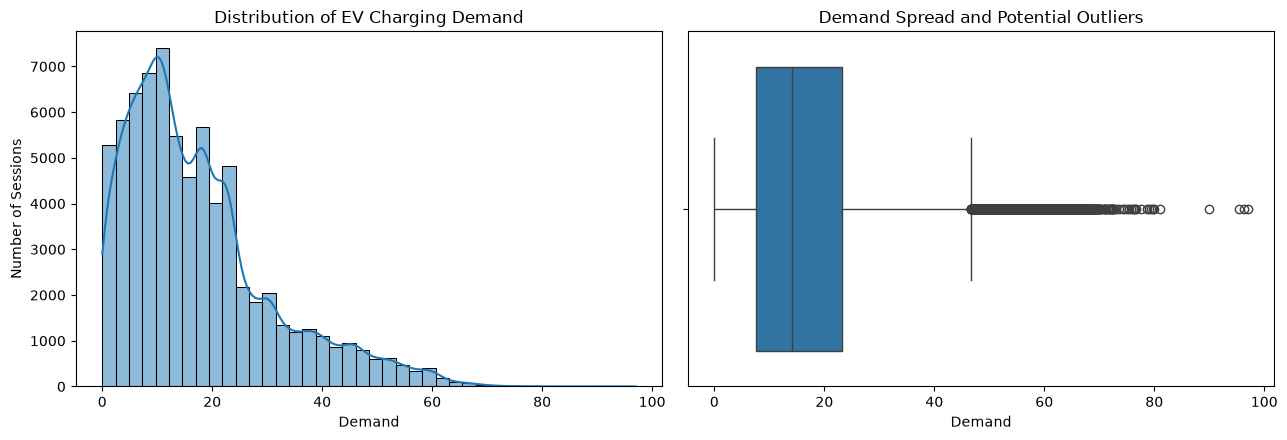

Demand skewness: 1.190
Demand median: 14.100
Demand mean: 17.440


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# A histogram shows how frequently different demand values occur.
sns.histplot(
    data=df,
    x="Demand",
    bins=40,
    kde=True,
    ax=axes[0],
)
axes[0].set_title("Distribution of EV Charging Demand")
axes[0].set_xlabel("Demand")
axes[0].set_ylabel("Number of Sessions")

# A box plot provides a compact view of the median, spread,
# and potential outlying observations.
sns.boxplot(
    data=df,
    x="Demand",
    ax=axes[1],
)
axes[1].set_title("Demand Spread and Potential Outliers")
axes[1].set_xlabel("Demand")

plt.tight_layout()
plt.show()

print(f"Demand skewness: {df['Demand'].skew():.3f}")
print(f"Demand median: {df['Demand'].median():.3f}")
print(f"Demand mean: {df['Demand'].mean():.3f}")

### Findings: Demand Distribution and Data Quality

The engineered dataset contains 72,826 records and 24 columns. No exact duplicate rows or missing values were detected in the engineered dataset, and the `Demand` column contains 72,826 observations.

The mean Demand is 17.44, while the median is 14.10. The standard deviation is 13.491, and the observed values range from 0.01 to 97.00.

The histogram shows a concentration of observations at relatively low-to-moderate demand values, followed by a long upper tail. The positive skewness of 1.190 supports the conclusion that the distribution is right-skewed.

The box plot identifies numerous potential upper-tail outliers. Using the interquartile range, the upper outlier fence is approximately 46.705. These observations should not automatically be removed because statistical outlier status alone does not establish that a record is invalid.

**Implications for modeling:** The demand distribution is not symmetric, so we should inspect residuals and compare model performance rather than assume that a simple linear model will adequately capture the relationship. We will retain the observed Demand values unless further investigation provides evidence of data errors.

## Demand Across Charging Infrastructure

This section compares session counts, mean demand, and median demand across locations, charger types, and charging companies.

The session count indicates how frequently a category appears in the data. Mean and median demand indicate the typical demand level using two different summaries. Reporting all three helps distinguish frequently used categories from categories with higher observed demand.


Demand summary by Location:


,session_count,mean_demand,median_demand
Location,,,
bus garage,29,28.588,29.910
accommodation,187,29.056,28.730
camping,1630,25.525,23.530
public parking lot,3394,17.188,15.995
public area,14076,17.900,14.530
company,7557,16.248,14.420
public institution,7023,17.399,14.420
apartment,14036,18.745,14.400
resort,8854,17.281,14.005



Demand summary by ChargerType:


,session_count,mean_demand,median_demand
ChargerType,,,
1,14930,18.946,17.15
0,57896,17.052,13.10



Demand summary by ChargerCompany:


,session_count,mean_demand,median_demand
ChargerCompany,,,
1,45709,17.886,14.65
0,27117,16.689,13.29


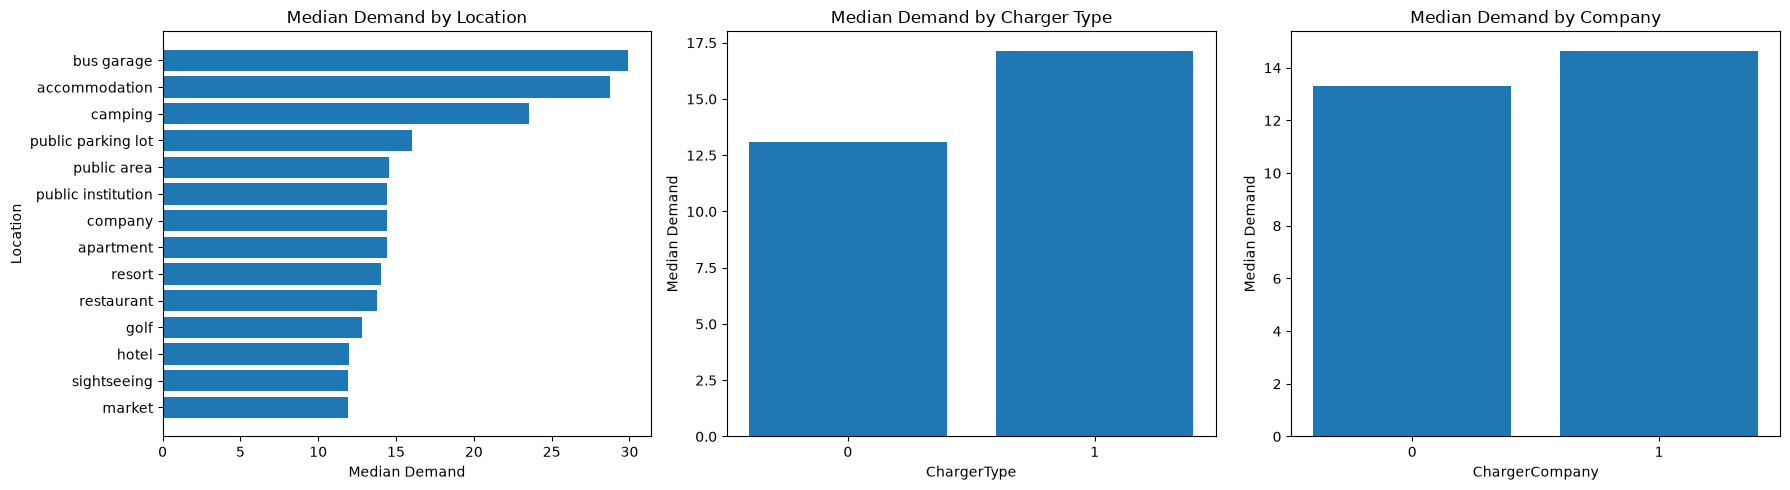

In [3]:
group_columns = [
    "Location",
    "ChargerType",
    "ChargerCompany",
]

group_summaries = {}

for column in group_columns:
    summary = (
        df.groupby(column, observed=True)["Demand"]
        .agg(
            session_count="size",
            mean_demand="mean",
            median_demand="median",
        )
        .sort_values("median_demand", ascending=False)
    )

    group_summaries[column] = summary

    print(f"\nDemand summary by {column}:")
    display(summary.round(3))


# Plot median demand for the three category dimensions.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

location_summary = group_summaries["Location"].sort_values(
    "median_demand"
)

axes[0].barh(
    location_summary.index.astype(str),
    location_summary["median_demand"],
)
axes[0].set_title("Median Demand by Location")
axes[0].set_xlabel("Median Demand")
axes[0].set_ylabel("Location")

for ax, column, title in [
    (axes[1], "ChargerType", "Median Demand by Charger Type"),
    (axes[2], "ChargerCompany", "Median Demand by Company"),
]:
    summary = group_summaries[column].sort_values("median_demand")

    ax.bar(
        summary.index.astype(str),
        summary["median_demand"],
    )
    ax.set_title(title)
    ax.set_xlabel(column)
    ax.set_ylabel("Median Demand")

plt.tight_layout()
plt.show()

### Findings: Demand by Location, Charger Type, and Company

The category-level analysis reveals differences in observed demand across locations, charger types, and charging company codes.

**Location:** Bus garage has the highest observed median Demand at 29.91, but this category contains only 29 sessions. Accommodation has a median of 28.73 across 187 sessions. Both estimates should be interpreted cautiously because their sample sizes are relatively small. Camping has a median Demand of 23.53 across 1,630 sessions, making it another category with comparatively high observed demand.

Apartment and public area contribute the largest numbers of sessions, with 14,036 and 14,076 records respectively. Their median Demand values are 14.40 and 14.53. This demonstrates that a category with many charging sessions does not necessarily have the highest typical demand per session.

Hotel has a median Demand of 12.00, while market and sightseeing have medians of 11.92 and 11.93, respectively.

**Charger type:** Category code 1 has a mean Demand of 18.946 and median Demand of 17.15, compared with a mean of 17.052 and median of 13.10 for category code 0. Thus, code 1 has higher observed mean and median demand in this dataset. The human-readable meanings of these codes have not been established from the available dataset description.

**Charging company:** Company code 1 has a mean Demand of 17.886 and median Demand of 14.65, compared with a mean of 16.689 and median of 13.29 for code 0. These are observed descriptive differences; the identity of each company code is not available in the current schema.

**Implications:** Location, charger type, and charging company are reasonable candidate variables for further investigation in the supervised models. However, these summaries alone do not establish causation, statistical significance, or the independent predictive contribution of each variable. Sample size should be considered when interpreting differences between categories.

Hourly charging summary:


,session_count,mean_demand,median_demand
StartHour,,,
0,919,26.547,24.090
1,449,25.319,22.580
2,200,25.037,20.970
3,134,20.250,18.200
4,190,18.260,14.090
5,549,17.246,13.460
6,1214,16.985,14.365
7,2291,16.811,14.820
8,4143,17.517,14.720


Demand summary by weekday:


,session_count,mean_demand,median_demand
StartDayName,,,
Monday,10321,17.353,14.05
Tuesday,10644,17.102,13.80
Wednesday,10878,17.528,14.13
Thursday,11050,17.623,14.38
Friday,11008,17.305,13.96
Saturday,9939,17.415,14.02
Sunday,8986,17.806,14.45


Demand summary by time of day:


,session_count,mean_demand,median_demand
TimeOfDay,,,
Night,2441,23.115,19.90
Morning,18187,15.290,12.29
Afternoon,20877,14.247,11.20
Evening,31321,20.375,18.03


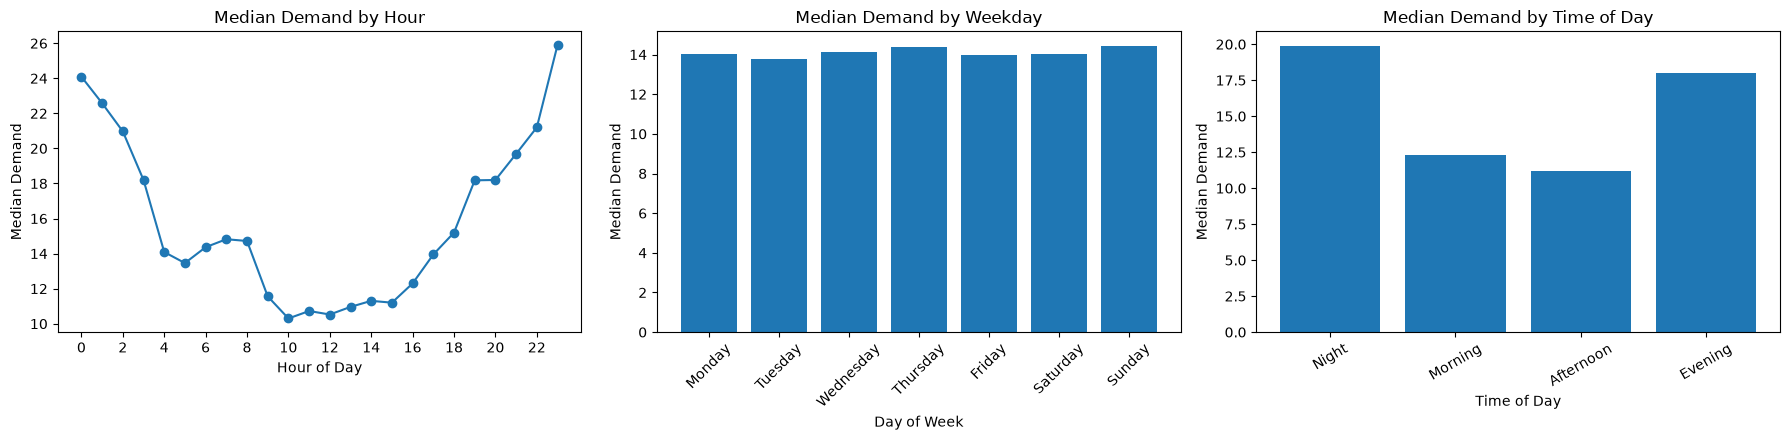

In [4]:
# Summarize the number of sessions and typical demand by hour.
hourly_summary = (
    df.groupby("StartHour")["Demand"]
    .agg(
        session_count="size",
        mean_demand="mean",
        median_demand="median",
    )
    .reindex(range(24))
)

print("Hourly charging summary:")
display(hourly_summary.round(3))


# Use an explicit weekday order so that the plot follows
# the calendar rather than sorting weekday names alphabetically.
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

weekday_summary = (
    df.groupby("StartDayName", observed=True)["Demand"]
    .agg(
        session_count="size",
        mean_demand="mean",
        median_demand="median",
    )
    .reindex(weekday_order)
)

print("Demand summary by weekday:")
display(weekday_summary.round(3))


# Reorder broad time-of-day categories chronologically.
time_order = ["Night", "Morning", "Afternoon", "Evening"]

time_summary = (
    df.groupby("TimeOfDay", observed=True)["Demand"]
    .agg(
        session_count="size",
        mean_demand="mean",
        median_demand="median",
    )
    .reindex(time_order)
)

print("Demand summary by time of day:")
display(time_summary.round(3))


# Visualize temporal summaries.
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

axes[0].plot(
    hourly_summary.index,
    hourly_summary["median_demand"],
    marker="o",
)
axes[0].set_title("Median Demand by Hour")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Median Demand")
axes[0].set_xticks(range(0, 24, 2))

axes[1].bar(
    weekday_summary.index,
    weekday_summary["median_demand"],
)
axes[1].set_title("Median Demand by Weekday")
axes[1].set_xlabel("Day of Week")
axes[1].set_ylabel("Median Demand")
axes[1].tick_params(axis="x", rotation=45)

axes[2].bar(
    time_summary.index,
    time_summary["median_demand"],
)
axes[2].set_title("Median Demand by Time of Day")
axes[2].set_xlabel("Time of Day")
axes[2].set_ylabel("Median Demand")
axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### Findings: Temporal Demand Patterns

The temporal analysis indicates that observed EV charging demand varies more noticeably by hour and broad time-of-day category than by weekday.

**Hourly demand:** The median Demand is relatively low during the late morning and midday. The lowest observed hourly median is 10.30 at 10:00, followed by 10.525 at 12:00. Median Demand then rises toward the late evening, reaching 25.90 at 23:00. The median at midnight is also relatively high at 24.09.

**Session volume:** The highest number of charging sessions starts at 18:00, with 6,506 sessions, followed by 17:00 with 6,355 sessions. Although 23:00 has the highest observed hourly median Demand, it has 1,784 sessions. This distinction shows that typical per-session demand and the frequency of charging sessions measure different aspects of utilization.

**Weekday demand:** Median Demand varies from 13.80 on Tuesday to 14.45 on Sunday, while mean Demand ranges from 17.102 on Tuesday to 17.806 on Sunday. The observed weekday medians are broadly similar. These descriptive results do not establish that the differences are statistically significant.

**Broad time-of-day categories:** Evening contains the largest number of sessions, with 31,321 records, a mean Demand of 20.375, and a median of 18.03. Night has a mean Demand of 23.115 and median of 19.90 across 2,441 sessions. Morning and Afternoon have lower median values of 12.29 and 11.20, respectively.

The broad Night category combines hours with different demand patterns, including relatively high medians around midnight and lower medians toward 04:00–05:00. Therefore, grouped statistics should be interpreted alongside the hourly results.

**Implications:** Time-based features appear useful to investigate during regression and classification. The hourly pattern may also inform time-series analysis and the dashboard. These findings are descriptive and should not be interpreted as causal relationships.

Validated duration observations: 69,450
Pearson correlation: 0.645
Spearman correlation: 0.631


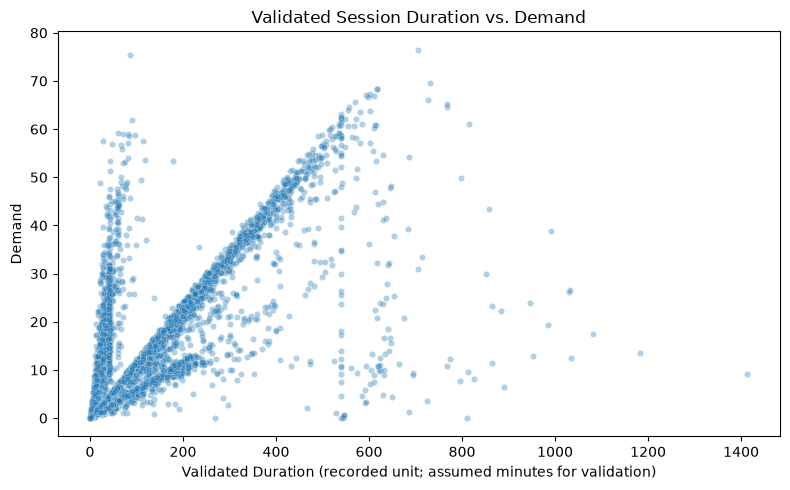

In [5]:
# Duration analysis is limited to observations whose durations
# passed the validation rule documented in Notebook 01.
duration_df = df.dropna(
    subset=["DurationValidated", "Demand"]
).copy()

pearson_corr = duration_df[
    ["DurationValidated", "Demand"]
].corr(method="pearson").iloc[0, 1]

spearman_corr = duration_df[
    ["DurationValidated", "Demand"]
].corr(method="spearman").iloc[0, 1]

print(f"Validated duration observations: {len(duration_df):,}")
print(f"Pearson correlation: {pearson_corr:.3f}")
print(f"Spearman correlation: {spearman_corr:.3f}")

# Sample points for a readable plot rather than rendering
# every session in the scatter plot.
sample_df = duration_df.sample(
    n=min(5000, len(duration_df)),
    random_state=42,
)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=sample_df,
    x="DurationValidated",
    y="Demand",
    alpha=0.35,
    s=20,
)
plt.title("Validated Session Duration vs. Demand")
plt.xlabel("Validated Duration (recorded unit; assumed minutes for validation)")
plt.ylabel("Demand")
plt.tight_layout()
plt.show()

# 7. EDA Summary, Key Findings, and Conclusion

## 7.1 Objective Achieved

The objective of this notebook was to investigate EV charging demand patterns across the dataset, including its distribution, charging locations, charger categories, temporal characteristics, and relationship with validated session duration.

The analysis provides evidence-based observations that will inform the supervised machine-learning models, time-series forecasting, and Streamlit dashboard.

## 7.2 Dataset Profile

The engineered dataset contained **72,826 records and 24 columns**.

No exact duplicate rows or missing `Demand` values were detected in the EDA notebook.

The categorical variables included 14 distinct locations and two codes each for `ChargerType` and `ChargerCompany`. The meanings of the numeric category codes were not established from the available dataset description.

## 7.3 Demand Distribution

The reported Demand statistics were:

| Statistic | Value |
|---|---:|
| Mean | 17.440 |
| Median | 14.100 |
| Standard deviation | 13.491 |
| Minimum | 0.010 |
| First quartile | 7.530 |
| Third quartile | 23.200 |
| Maximum | 97.000 |
| Skewness | 1.190 |

The histogram and positive skewness indicate a right-skewed distribution. The mean exceeds the median, and the distribution has a long upper tail.

The interquartile range is 15.67, giving a conventional upper Tukey fence of approximately 46.705. The box plot shows potential upper-tail outliers. However, statistical outlier status alone does not establish that a record is erroneous, so these observations were not automatically removed.

**Modeling implication:** Model performance and residuals should be examined rather than assuming that Demand follows a symmetric distribution or that extreme observations are invalid.

## 7.4 Demand by Location, Charger Type, and Company

### Location

Bus garage has the highest observed median Demand at 29.91, but it contains only 29 sessions. Accommodation has a median of 28.73 across 187 sessions, while camping has a median of 23.53 across 1,630 sessions.

Apartment and public area account for the largest numbers of sessions, with 14,036 and 14,076 records respectively. Their median Demand values are 14.40 and 14.53.

These observations demonstrate that the categories with the highest typical per-session Demand are not necessarily those with the highest session counts. The small sample sizes for bus garage and accommodation also require caution when interpreting their medians.

### Charger type

ChargerType code 1 has a mean Demand of 18.946 and median of 17.15 across 14,930 sessions. Code 0 has a mean of 17.052 and median of 13.10 across